Slope: 1.2873573700109315
C: 9.90860619032653
Squared difference is: 10639.5732639414
Mean square error is: 107.4704370095091


Enter value for prediction:  40


Predicted value for 40.0 is: 61.40290099076379


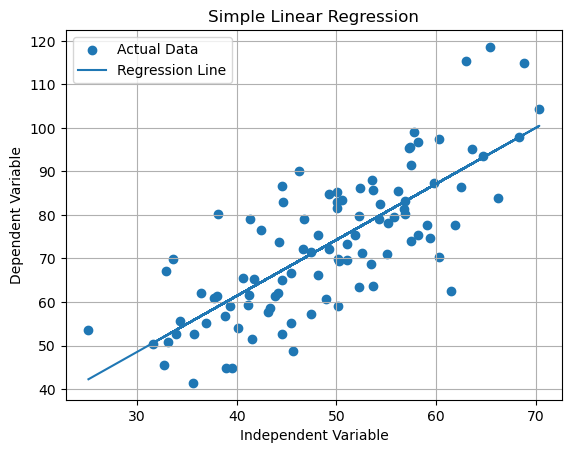

In [16]:
import pandas as pd
import math
import matplotlib.pyplot as plt

data = pd.read_csv('data.csv')

class simplelinearregression():
    def __init__(self):
        self.slope_numerator = 0
        self.slope_denominator = 0
        self.sum = 0
        self.pred_y = []

    def fit(self, data):
        df = pd.DataFrame(data)
        numerical_data = df.select_dtypes(include='number')
        self.x = numerical_data.iloc[:, [0]]
        self.y = numerical_data.iloc[:, [1]]
        self.x1 = self.x.mean().item()
        self.y1 = self.y.mean().item()
        for i in range(0, len(self.x), 1):
            self.x2 = self.x.iat[i, 0]
            self.y2 = self.y.iat[i, 0]
            self.slope_numerator = self.slope_numerator + (self.x2-self.x1)*(self.y2-self.y1)
            self.slope_denominator = self.slope_denominator + ((self.x2-self.x1)**2)
        self.m = self.slope_numerator/self.slope_denominator
        self.c = self.y1-self.m*self.x1

        print("Slope:", self.m)
        print("C:", self.c)

    def predict(self, X, y=None):
        if y is None:
            self.Y = self.m*X+self.c
            print(f"Predicted value for {X} is:", self.Y)
        else:
            self.Y = self.m*X+self.c
            self.sum = self.sum+((y-self.Y)**2)
            self.pred_y.append(self.Y)
            return self.sum

    def visualize(self, n, a):
        plt.scatter(self.x, self.y, label="Actual Data")
        plt.plot(self.x, self.pred_y, label="Regression Line")
        plt.xlabel("Independent Variable")
        plt.ylabel("Dependent Variable")
        plt.title("Simple Linear Regression")
        plt.legend()
        plt.grid()
        plt.show()


model = simplelinearregression()
df = pd.DataFrame(data)
numerical_data = df.select_dtypes(include='number')
x = numerical_data.iloc[:, [0]]
y = numerical_data.iloc[:, [1]]
n = len(x)
model.fit(data)
for i in range(0, n):
    a = float(x.iat[i, 0])
    b = float(y.iat[i, 0])
    total = model.predict(a, b)
print("Squared difference is:", total)
mse = total/n
print("Mean square error is:", mse)
value = float(input("Enter value for prediction: "))
model.predict(value)
model.visualize(n, a)